# 04 — Explainability & Business Insights

**Phase 6** (see `CONTINUITY.md`). Why does the model flag a customer, and what can the business do about it?

Code: `src/explain.py` (run `python -m src.explain`, ~30 s). It computes **SHAP (Shapley) values** for the saved Random Forest on the original 19 customer features, so every explanation reads in business terms (`Contract = Month-to-month`), not one-hot columns.

- A SHAP value is how much one feature moved this customer's churn probability away from the average prediction. Values add up: average + sum of SHAP values = this customer's prediction.
- Backend: `shap.PermutationExplainer` when `shap` is installed; otherwise a built-in implementation of the same permutation-sampling algorithm (verified against exact Shapley values in `tests/test_explain.py`).
- Permutation importance (ROC-AUC drop when a feature is shuffled) is computed as an independent cross-check.

In [1]:
import json, sys
from pathlib import Path
import matplotlib.pyplot as plt
import pandas as pd

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

def show(png, width=10):
    img = plt.imread(ROOT / "reports" / "figures" / png)
    h, w = img.shape[:2]
    fig, ax = plt.subplots(figsize=(width, width * h / w)); ax.imshow(img); ax.axis("off"); plt.show()

ex = json.loads((ROOT / "reports" / "explainability.json").read_text())
print("Backend:", ex["backend"])
print(f"{ex['n_customers_global']} test customers, {ex['n_background']} background customers, "
      f"{ex['n_permutations']} permutations each")
print(f"Average prediction (base value): {ex['base_value']}  |  additivity error: {ex['additivity_error']}")

Backend: built-in sampling Shapley (install `shap` for the library)
200 test customers, 100 background customers, 100 permutations each
Average prediction (base value): 0.4363  |  additivity error: 0.02077


> **Note on the base value (0.44, not 0.265):** the model was trained with `class_weight='balanced'`, which shifts its probabilities upward. The *ranking* of customers is unaffected (that's what ROC-AUC measures) and the 0.49 threshold was chosen on this scale. If calibrated probabilities are ever needed (e.g. "expected number of churners"), wrap the model in `CalibratedClassifierCV`.

## 6.1 Global drivers of churn

                  mean |SHAP|  ROC-AUC drop (permutation)
Contract               0.1105                      0.0705
InternetService        0.0621                      0.0152
tenure                 0.0504                      0.0228
OnlineSecurity         0.0394                      0.0056
TotalCharges           0.0320                      0.0142
TechSupport            0.0300                      0.0039
PaymentMethod          0.0229                      0.0025
MonthlyCharges         0.0184                      0.0012
OnlineBackup           0.0165                      0.0011
StreamingTV            0.0140                      0.0006
StreamingMovies        0.0136                      0.0011
DeviceProtection       0.0092                     -0.0002
MultipleLines          0.0086                      0.0012
PaperlessBilling       0.0079                      0.0010
Dependents             0.0035                      0.0002
SeniorCitizen          0.0026                      0.0006
Partner       

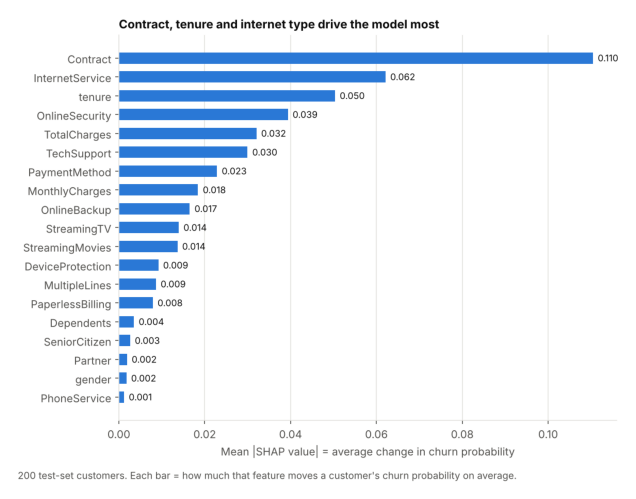

In [2]:
imp = pd.Series(ex["global_importance"]).rename("mean |SHAP|")
pi = pd.Series(ex["permutation_importance_auc_drop"]).rename("ROC-AUC drop (permutation)")
print(pd.concat([imp, pi], axis=1).sort_values("mean |SHAP|", ascending=False).round(4).to_string())
show("11_shap_global_importance.png", 8)

Both methods agree on the top of the list: **Contract** dominates, followed by **InternetService**, **tenure**, **OnlineSecurity**, **TechSupport** and the charges. Gender, PhoneService and StreamingTV/Movies contribute almost nothing — matching the Phase 2 EDA.

### Direction: which values push toward churn?

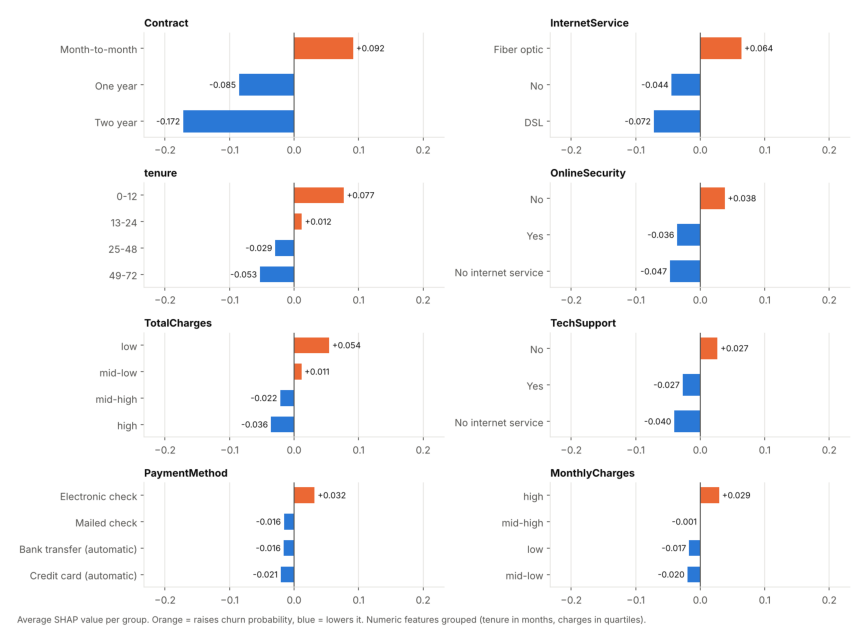

In [3]:
show("12_shap_by_value.png", 11)

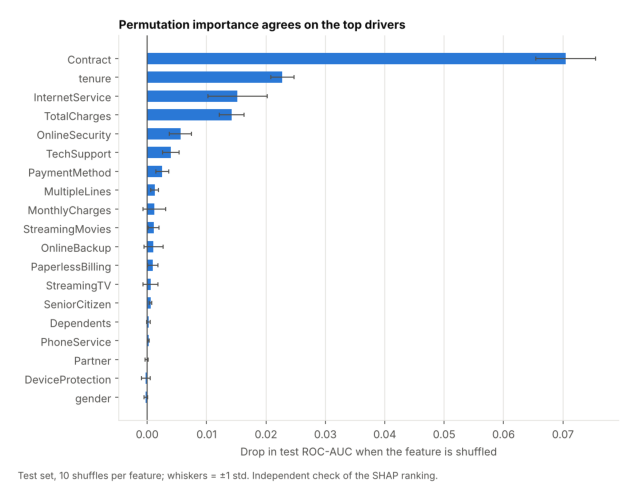

In [4]:
show("14_permutation_importance.png", 8)

## 6.2 Individual customers (waterfall plots)
Three test-set customers: a confident churner, a confident stayer, and one right at the decision threshold. Orange bars push toward churn, blue toward staying; read bottom to top from the dashed average line to the customer's prediction.

high_risk: p=0.904 (churned)  top reasons -> {'Contract = Month-to-month': 0.118, 'tenure = 1': 0.092, 'TotalCharges = 84.85': 0.061}
borderline: p=0.49 (stayed)  top reasons -> {'Contract = Month-to-month': 0.087, 'InternetService = Fiber optic': 0.072, 'TechSupport = Yes': -0.038}
low_risk: p=0.027 (stayed)  top reasons -> {'Contract = One year': -0.092, 'OnlineSecurity = No internet service': -0.049, 'InternetService = No': -0.049}


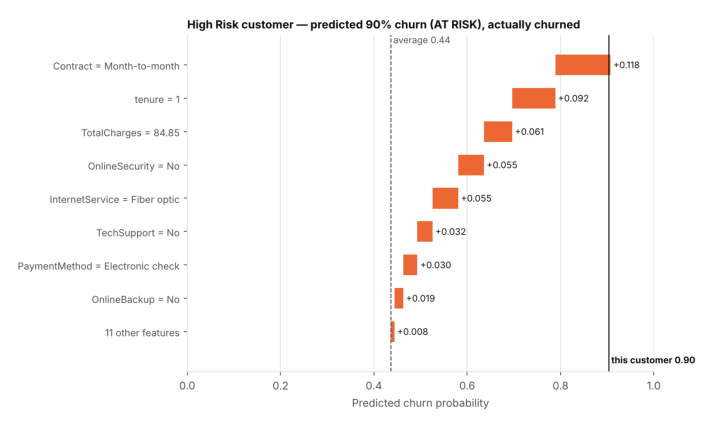

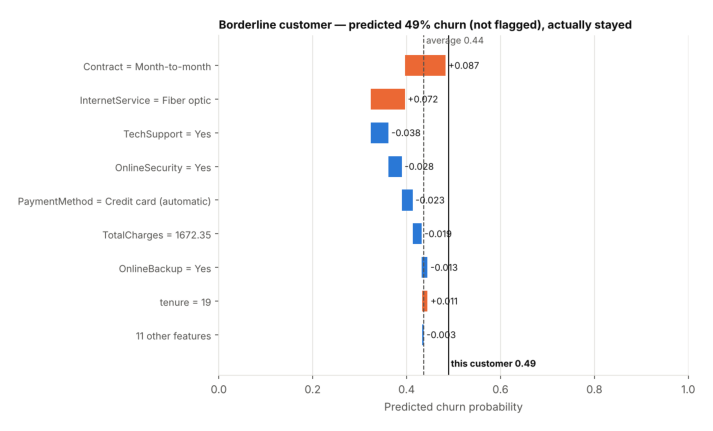

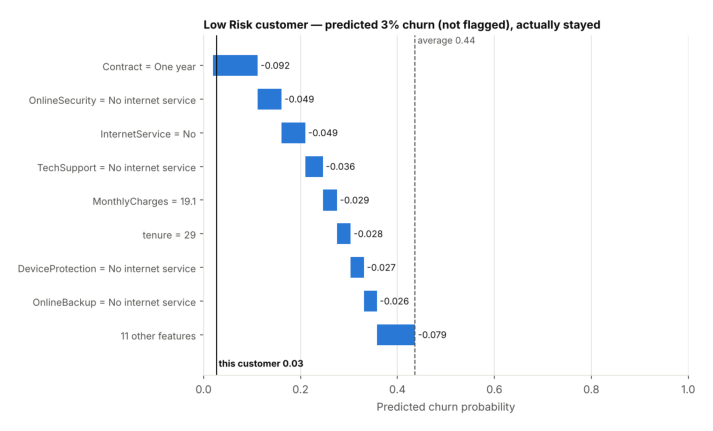

In [5]:
for tag in ("high_risk", "borderline", "low_risk"):
    c = ex["customers"][tag]
    print(f"{tag}: p={c['probability']} ({c['actual']})  top reasons -> {c['top_reasons']}")
    show(f"13_shap_customer_{tag}.png", 9)

The **borderline** customer (49%, actually stayed) shows why the threshold matters: month-to-month + fiber push toward churn, but having TechSupport pulls back — exactly the trade-off a retention team would want to see before calling.

## 6.3 Top 5 churn drivers → retention actions

| # | Driver (SHAP) | What the model learned | Retention action |
|---|---|---|---|
| 1 | **Contract** (0.11) | Month-to-month **+0.09**; two-year **−0.17** — the biggest swing of any feature | Offer a discount or perk for switching to a 1- or 2-year contract, targeted at month-to-month customers flagged AT RISK |
| 2 | **InternetService** (0.06) | Fiber optic **+0.06**; DSL **−0.07** | Investigate fiber price/quality complaints; price-match or speed upgrade offers for at-risk fiber customers |
| 3 | **tenure** (0.05) | First 12 months **+0.08**; 4+ years **−0.05** | Structured onboarding for new customers: check-in calls at months 1, 3 and 6, early-life loyalty credit |
| 4 | **OnlineSecurity** (0.04) | Without it **+0.04**; with it **−0.04** | Bundle OnlineSecurity free for 3–6 months for at-risk internet customers |
| 5 | **TechSupport** (0.03) | Without it **+0.03**; with it **−0.03** | Same bundle as #4 — or proactive support outreach to fiber customers without TechSupport |

Also notable: **electronic check** payers **+0.03** → incentivise switching to auto-pay (small bill credit).

**Caveat:** SHAP explains what the *model* relies on, which reflects correlation in historical data, not proven causation. Each action above should be validated with an A/B test (offer vs. no offer on flagged customers) before a full rollout.

## Running with the official `shap` library
`pip install shap` and re-run `python -m src.explain` — it switches backend automatically. For SHAP's own plots:

In [6]:
try:
    import shap, joblib
    from src.data_prep import clean, split
    from src.load_data import load_raw
    bundle = joblib.load(ROOT / "models" / "churn_model.pkl")
    X_train, X_test, _, _ = split(clean(load_raw()))
    f = lambda df: bundle["pipeline"].predict_proba(df)[:, 1]
    explainer = shap.PermutationExplainer(f, X_train.sample(100, random_state=42))
    sv = explainer(X_test.sample(200, random_state=42))
    shap.plots.bar(sv)
    shap.plots.waterfall(sv[0])
except ImportError:
    print("shap not installed here - figures above use the built-in Shapley backend. Run `pip install shap` to use this cell.")

shap not installed here - figures above use the built-in Shapley backend. Run `pip install shap` to use this cell.
